In [1]:
#import Libraries

import torch
import torch.optim as op
import torch.utils
import torch.nn.functional as F
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import numpy as np
import PIL
import matplotlib
from matplotlib import pyplot
import scipy.signal
import io

In [13]:
fasion_dataset_file='./FSN/train-images-idx3-ubyte'
my_device = 'cuda'
sub_set_size = 40000 #using 20000 out of 60000 (VRAM Limitation)

In [14]:
#reading dataset

data_io = open(fasion_dataset_file,'rb')
data_io.seek(16)

raw_data=data_io.read(60000*28*28)
dataset=np.ndarray((60000,1,28,28),dtype=np.uint8,buffer=raw_data)

dataset=np.float32(dataset/255.0)

In [15]:
#Up Scale ... 28x28 to 128x128
Transform=T.Compose([T.ToPILImage(),T.Scale(128),T.ToTensor()])

In [16]:
img_tensor=torch.tensor(
    np.ndarray(shape=(sub_set_size,1,128*128)),dtype=torch.float32,device=my_device
    )

In [18]:
for i in range(sub_set_size):
    scaled_img=Transform(dataset[i,0]).to(my_device)
    img_tensor[i,0]=scaled_img.reshape(128*128)

In [19]:
random_input=torch.randn((sub_set_size,64),dtype=torch.float32,device='cuda')

In [20]:
in_feature=128*128
ns_vec_size=64

Discriminator=nn.Sequential(
    
    nn.Linear(in_feature, 200),
    nn.LeakyReLU(0.01),
    nn.Linear(200, 64),
    nn.LeakyReLU(0.01),
    nn.Linear(64, 1),
    nn.Sigmoid()
)#.double()

Generator = nn.Sequential(
    nn.Linear(ns_vec_size, 400),
    nn.LeakyReLU(0.01),
    nn.Linear(400, 256),
    nn.LeakyReLU(0.01),
    nn.Linear(256,in_feature),
    nn.Sigmoid()

)#.double()

Generator.to(my_device)
Discriminator.to(my_device)

Sequential(
  (0): Linear(in_features=16384, out_features=200, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=200, out_features=64, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=64, out_features=1, bias=True)
  (5): Sigmoid()
)

In [21]:
optG=torch.optim.Adam(Generator.parameters(),lr=0.0003)
optD=torch.optim.Adam(Discriminator.parameters(),lr=0.0003)

Generator.train()
Discriminator.train()

Sequential(
  (0): Linear(in_features=16384, out_features=200, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=200, out_features=64, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=64, out_features=1, bias=True)
  (5): Sigmoid()
)

In [22]:
packed_td=torch.utils.data.TensorDataset(img_tensor,random_input)

In [23]:
with torch.no_grad():
    test1=Discriminator(img_tensor[0,0])

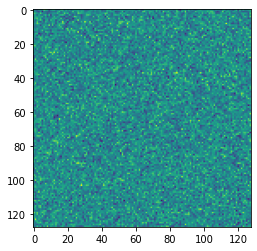

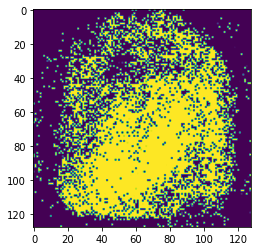

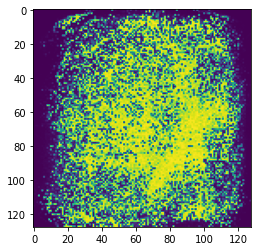

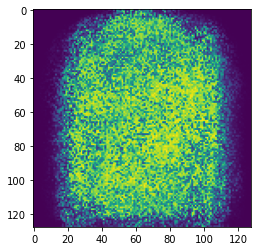

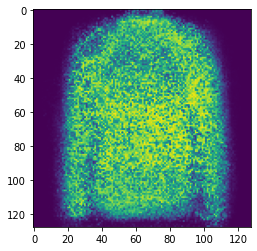

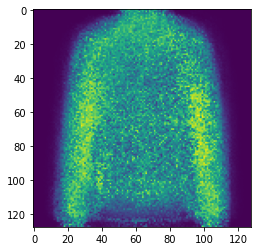

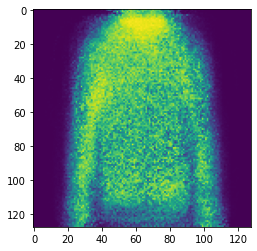

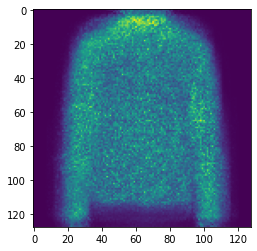

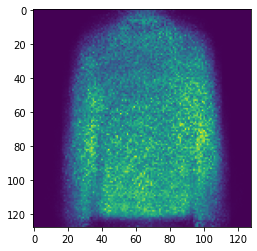

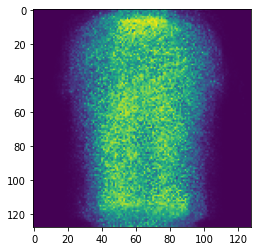

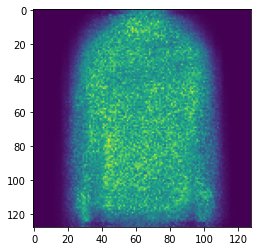

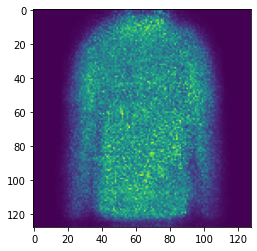

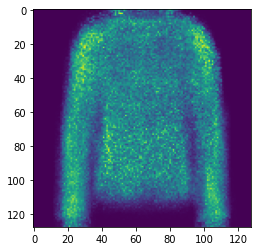

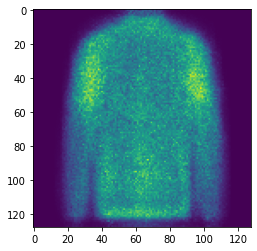

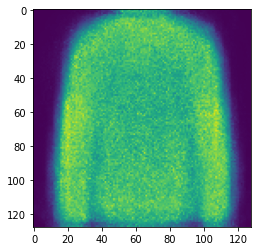

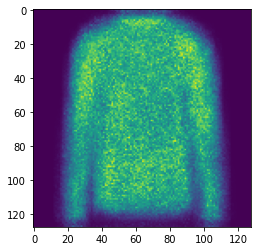

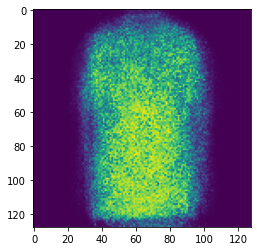

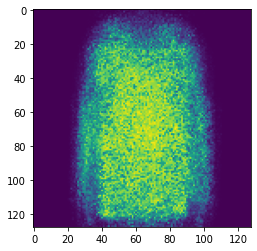

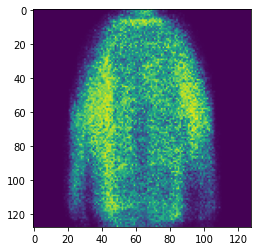

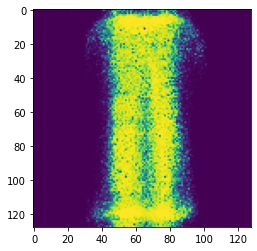

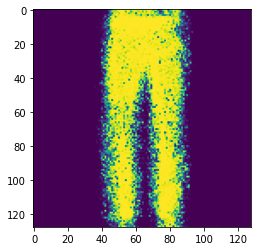

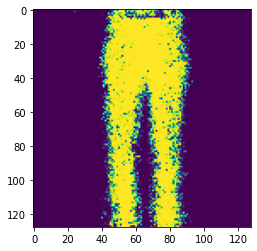

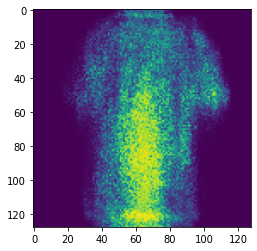

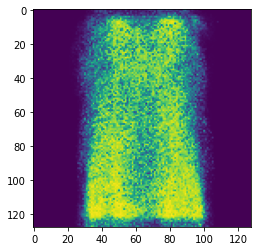

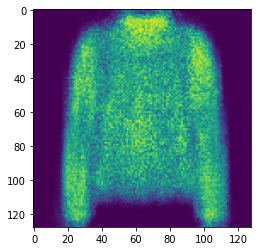

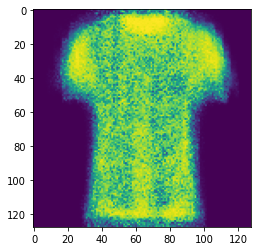

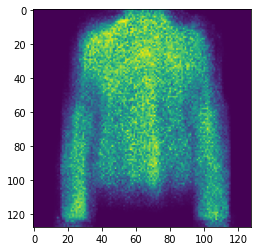

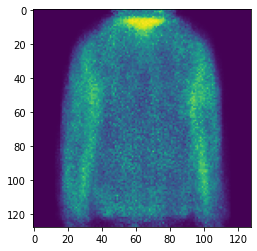

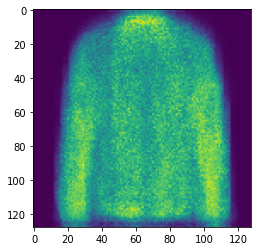

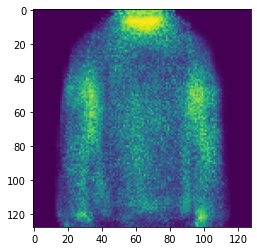

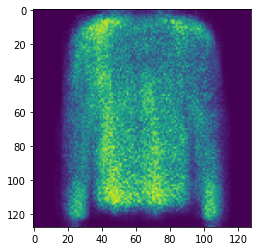

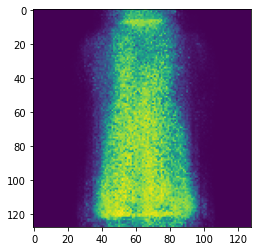

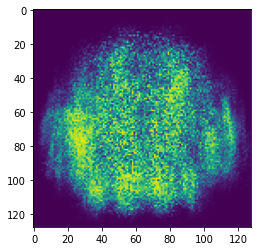

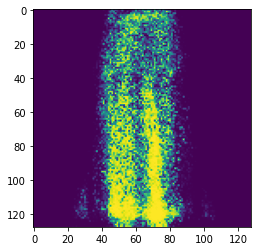

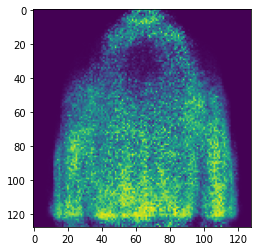

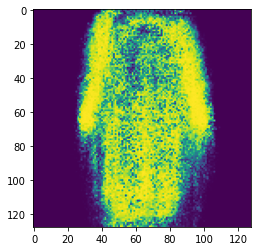

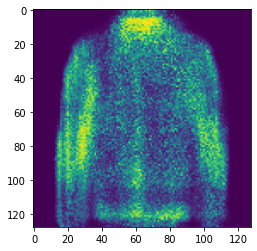

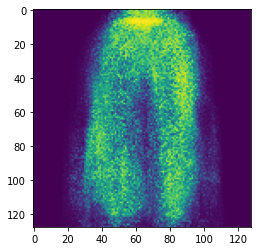

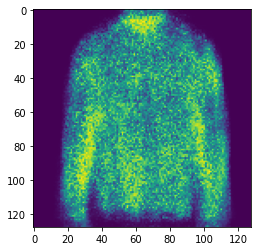

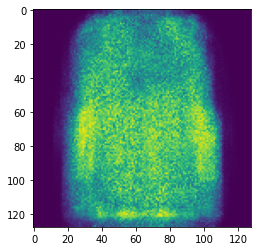

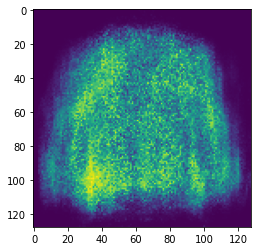

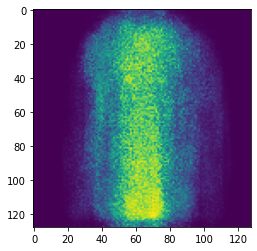

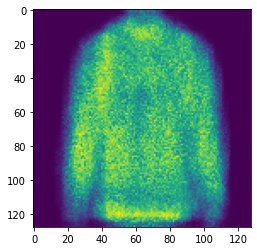

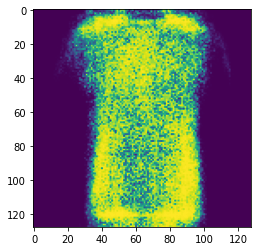

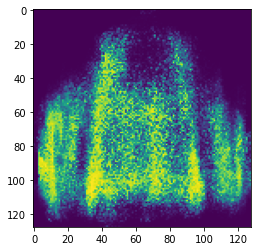

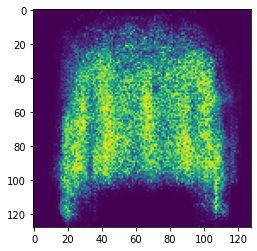

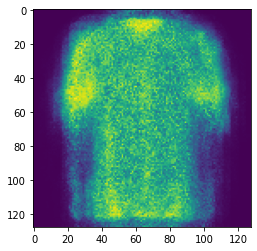

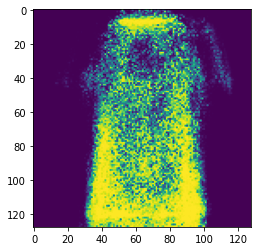

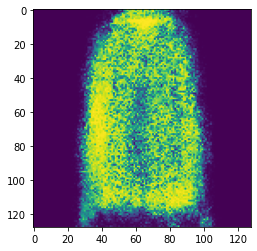

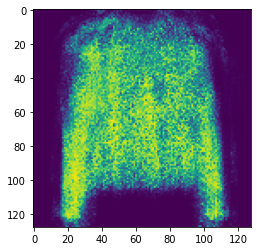

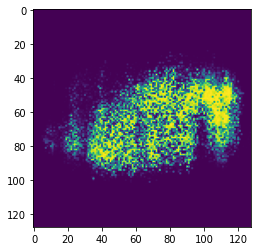

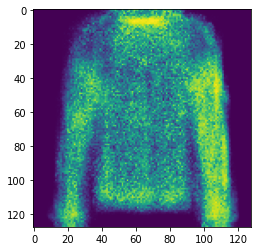

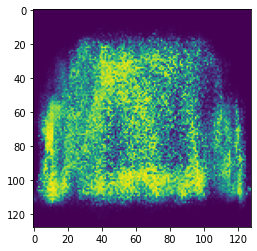

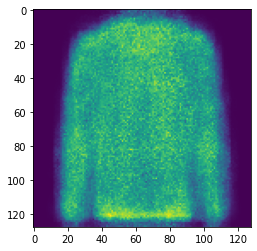

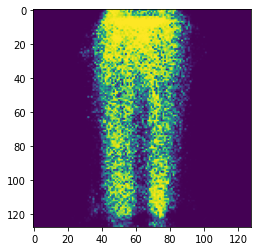

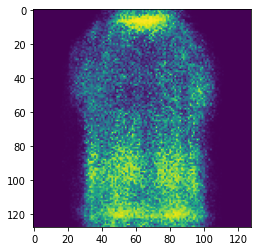

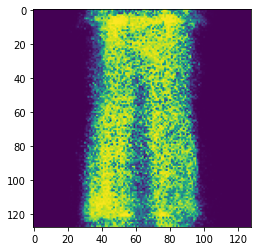

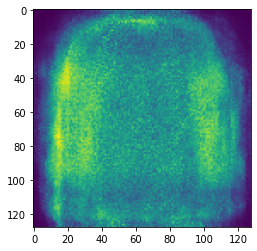

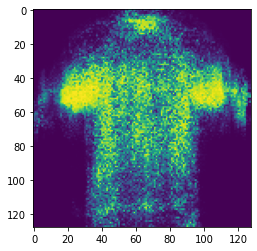

KeyboardInterrupt: 

In [24]:
#Train the Discriminator

for i in range(30):
    c=0

    loss=torch.nn.BCELoss()
    DL=torch.utils.data.DataLoader(packed_td,10,shuffle=True)
    KK=enumerate(DL)
    for idx,(r_im,rnd_ns) in KK:
        f_im=torch.tensor(0)
        with torch.no_grad():
            f_im=Generator(rnd_ns)

        disc_real = Discriminator(r_im)
        DLoss = loss(disc_real, torch.ones_like(disc_real)) 
        Discriminator.zero_grad()
        DLoss.backward()
        #optD.step()
        
        
        disc_fake = Discriminator(f_im)
        DLoss = loss(disc_fake, torch.zeros_like(disc_fake)) 
        #Discriminator.zero_grad()
        DLoss.backward()
        optD.step()
        
        
        Generator.zero_grad()
        f_im=Generator(rnd_ns)
        disc_fake2 = Discriminator(f_im).view(-1)
        lossD_fake = loss(disc_fake2, torch.ones_like(disc_fake2))
        
        
        lossD_fake.backward()
        optG.step()
        
        if c%1000 == 0 :
            with torch.no_grad():
                pyplot.imshow(f_im[0].cpu().reshape((128,128)))
                pyplot.pause(0.01)
        c = c + 1
    
    

In [ ]:
torch.save(Generator,'./GANs/fasion_gen.nn')
torch.save(Discriminator,'./GANs/fasion_dsc.nn')